# Task 2: Customer Segmentation Analysis Using K-Means

## Objective

The objective of this project is to group customers into meaningful segments using K-Means clustering based on demographic information and spending behaviour.

## Dataset

The dataset contains the following features:

* ID
* Gender
* Ever_Married
* Age
* Graduated
* Profession
* Work_Experience
* Spending_Score
* Family_Size
* Var_1
* Segmentation (available in the training dataset)

## Methodology

1. Load and inspect the dataset.
2. Handle missing values and inconsistent data.
3. Perform descriptive statistical analysis.
4. Select behavioural and demographic features.
5. Encode categorical variables and standardise numerical features.
6. Determine the optimal K using the Elbow Method.
7. Apply K-Means clustering.
8. Visualise and profile the clusters.
9. Compare cluster sizes and recommend marketing strategies.


## 1. Load the Dataset

We load the training, test, and sample submission files. The training dataset will be used to develop and interpret the customer segmentation model. We will retain the test dataset's IDs for the final output if predictions or cluster assignments are required.


In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

train = pd.read_csv("C:\\Documents\\Certifications\\OASIS INFOBYTE\\OASIS\\DataAnalytics\\L1\\CustomerSegmentation\\dataset\\Train.csv")
test = pd.read_csv("C:\\Documents\\Certifications\\OASIS INFOBYTE\\OASIS\\DataAnalytics\\L1\\CustomerSegmentation\\dataset\\Test.csv")
sample_submission = pd.read_csv("C:\\Documents\\Certifications\\OASIS INFOBYTE\\OASIS\\DataAnalytics\\L1\\CustomerSegmentation\\dataset\\sample_submission.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

display(train.head())
display(test.head())
display(sample_submission.head())


Train shape: (8068, 11)
Test shape: (2627, 10)
Sample submission shape: (2627, 2)


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1
0,458989,Female,Yes,36,Yes,Engineer,0.0,Low,1.0,Cat_6
1,458994,Male,Yes,37,Yes,Healthcare,8.0,Average,4.0,Cat_6
2,458996,Female,Yes,69,No,NaN,0.0,Low,1.0,Cat_6
3,459000,Male,Yes,59,No,Executive,11.0,High,2.0,Cat_6
4,459001,Female,No,19,No,Marketing,NaN,Low,4.0,Cat_6


,ID,Segmentation
0,458989,A
1,458994,A
2,458996,A
3,459000,A
4,459001,A


## 2. Dataset Inspection

We examine column names, data types, missing values, duplicate records, and descriptive statistics to understand the dataset before preprocessing.


In [13]:

print("Training columns:")
print(train.columns.tolist())

print("\nDataset information:")
train.info()

print("\nDescriptive statistics:")
display(train.describe(include="all").T)

print("\nMissing values:")
display(train.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", train.duplicated().sum())

print("\nSegmentation label counts (if available):")
if "Segmentation" in train.columns:
    print(train["Segmentation"].value_counts(dropna=False))


Training columns:
['ID', 'Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession', 'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1', 'Segmentation']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8068 entries, 0 to 8067
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               8068 non-null   int64  
 1   Gender           8068 non-null   str    
 2   Ever_Married     7928 non-null   str    
 3   Age              8068 non-null   int64  
 4   Graduated        7990 non-null   str    
 5   Profession       7944 non-null   str    
 6   Work_Experience  7239 non-null   float64
 7   Spending_Score   8068 non-null   str    
 8   Family_Size      7733 non-null   float64
 9   Var_1            7992 non-null   str    
 10  Segmentation     8068 non-null   str    
dtypes: float64(2), int64(2), str(7)
memory usage: 693.5 KB

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,8068.0,NaN,NaN,NaN,463479.214551,2595.381232,458982.0,461240.75,463472.5,465744.25,467974.0
Gender,8068,2,Male,4417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ever_Married,7928,2,Yes,4643,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,8068.0,NaN,NaN,NaN,43.466906,16.711696,18.0,30.0,40.0,53.0,89.0
Graduated,7990,2,Yes,4968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profession,7944,9,Artist,2516,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Work_Experience,7239.0,NaN,NaN,NaN,2.641663,3.406763,0.0,0.0,1.0,4.0,14.0
Spending_Score,8068,3,Low,4878,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Family_Size,7733.0,NaN,NaN,NaN,2.850123,1.531413,1.0,2.0,3.0,4.0,9.0
Var_1,7992,7,Cat_6,5238,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


Work_Experience    829
Family_Size        335
Ever_Married       140
Profession         124
Graduated           78
Var_1               76
ID                   0
Gender               0
Age                  0
Spending_Score       0
Segmentation         0
dtype: int64


Duplicate rows: 0

Segmentation label counts (if available):
Segmentation
D    2268
A    1972
C    1970
B    1858
Name: count, dtype: int64


## 3. Data Cleaning

We standardise column names, remove duplicate records, convert numerical columns to numeric types, and handle missing values.

Numerical missing values will be filled using the median. Categorical missing values will be filled using the most frequent category, with an explicit fallback for columns that are entirely missing.

The customer ID and the known segmentation label will not be used as clustering features.


In [20]:

# Make independent working copies
train_df = train.copy()
test_df = test.copy()

def clean_column_names(data):
    data = data.copy()
    data.columns = (
        data.columns.astype(str)
        .str.strip()
        .str.replace(r"[^A-Za-z0-9]+", "_", regex=True)
        .str.strip("_")
    )
    return data

train_df = clean_column_names(train_df)
test_df = clean_column_names(test_df)

# Remove duplicate rows
train_df = train_df.drop_duplicates().copy()
test_df = test_df.drop_duplicates().copy()

# Standardise whitespace in text columns
for data in [train_df, test_df]:
    text_cols = data.select_dtypes(include=["object", "string"]).columns

    for col in text_cols:
        data[col] = data[col].apply(
            lambda value: value.strip() if isinstance(value, str) else value
        )
        data[col] = data[col].replace("", np.nan)

# Convert numerical columns safely
numeric_cols = ["Age", "Work_Experience", "Family_Size"]

for data in [train_df, test_df]:
    for col in numeric_cols:
        if col in data.columns:
            data[col] = pd.to_numeric(data[col], errors="coerce")

print("Training data after initial cleaning:")
display(train_df.head())

print("\nMissing values in training data:")
display(train_df.isnull().sum())



Training data after initial cleaning:


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A



Missing values in training data:


ID                   0
Gender               0
Ever_Married       140
Age                  0
Graduated           78
Profession         124
Work_Experience    829
Spending_Score       0
Family_Size        335
Var_1               76
Segmentation         0
dtype: int64

## 4. Descriptive Statistical Analysis

The dataset does not contain purchase amounts, transaction counts, or purchase dates. Consequently, traditional average purchase value, purchase frequency, and monetary customer lifetime value cannot be calculated.

Instead, we examine available customer characteristics, including age, work experience, family size, and spending score. These provide a useful descriptive overview of the customer base.


In [15]:

print("Numerical summary:")
display(
    train_df.select_dtypes(include=np.number)
    .describe()
    .T
)

for col in ["Gender", "Ever_Married", "Graduated",
            "Profession", "Spending_Score", "Var_1"]:
    if col in train_df.columns:
        print(f"\nDistribution of {col}:")
        display(train_df[col].value_counts(dropna=False))

if "Segmentation" in train_df.columns:
    print("\nKnown segmentation distribution:")
    display(
        train_df["Segmentation"]
        .value_counts(dropna=False)
    )

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
ID,8068.0,463479.214551,2595.381232,458982.0,461240.75,463472.5,465744.25,467974.0
Age,8068.0,43.466906,16.711696,18.0,30.00,40.0,53.00,89.0
Work_Experience,7239.0,2.641663,3.406763,0.0,0.00,1.0,4.00,14.0
Family_Size,7733.0,2.850123,1.531413,1.0,2.00,3.0,4.00,9.0



Distribution of Gender:


Gender
Male      4417
Female    3651
Name: count, dtype: int64


Distribution of Ever_Married:


...

Spending_Score
Low        4878
Average    1974
High       1216
Name: count, dtype: int64


Distribution of Var_1:


Var_1
Cat_6    5238
Cat_4    1089
Cat_3     822
Cat_2     422
Cat_7     203
Cat_1     133
Cat_5      85
NaN        76
Name: count, dtype: int64


Known segmentation distribution:


Segmentation
D    2268
A    1972
C    1970
B    1858
Name: count, dtype: int64

## 5. Exploratory Data Analysis

We explore age, family size, work experience, and spending-score distributions. These charts help us understand customer characteristics before clustering.


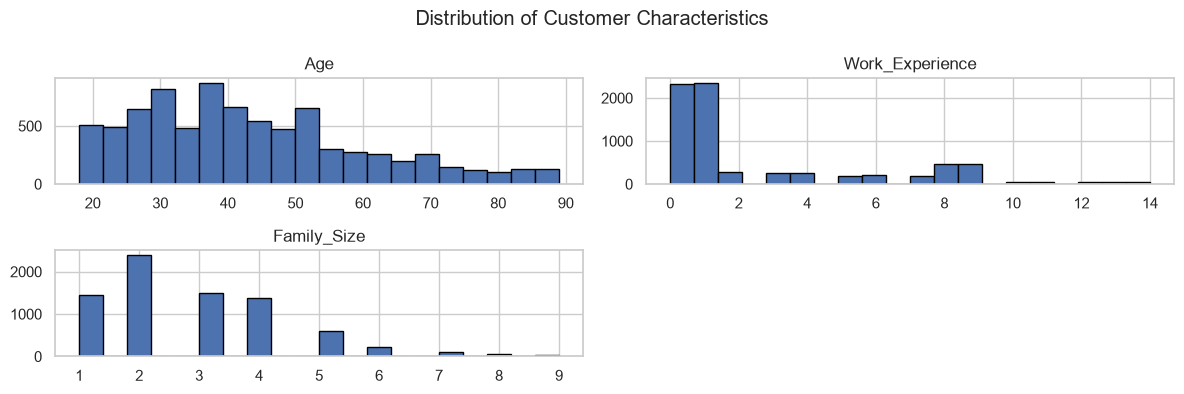

In [16]:

numeric_to_plot = [
    col for col in
    ["Age", "Work_Experience", "Family_Size"]
    if col in train_df.columns
]

train_df[numeric_to_plot].hist(
    figsize=(12, 4),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Customer Characteristics")
plt.tight_layout()
plt.show()

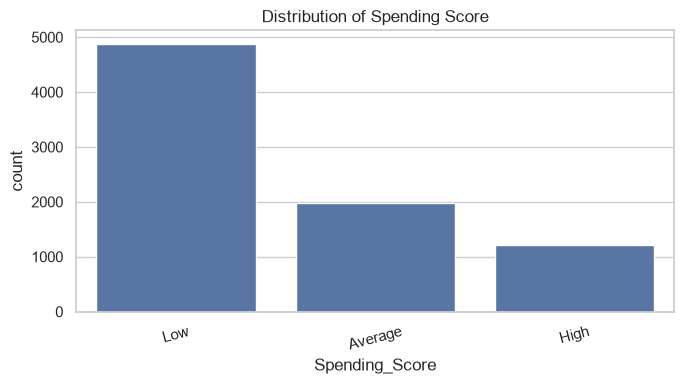

In [17]:

if "Spending_Score" in train_df.columns:
    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=train_df,
        x="Spending_Score",
        order=train_df["Spending_Score"].value_counts().index
    )

    plt.title("Distribution of Spending Score")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

## 6. Feature Selection

We use the following features to identify customer groups:

* **Age:** Represents the customer's age group.
* **Spending_Score:** Represents reported spending behaviour.
* **Family_Size:** Provides context about household size.
* **Work_Experience:** Provides an additional customer characteristic.
* **Gender, Ever_Married, Graduated, Profession, Var_1:** Optional categorical features that may improve segmentation.

We exclude `ID` because it is an identifier rather than a behavioural feature. We also exclude `Segmentation` from the K-Means inputs because it is an existing label in the training dataset; using it would leak the answer into an unsupervised clustering model.


## 7. Handle Missing Values, Encode Categories, and Standardise Features

K-Means requires numeric input. We impute missing values, encode categorical variables using one-hot encoding, and standardise the resulting features with `StandardScaler`.

We fit the preprocessing steps on the training data and reuse them on the test data. This ensures that both datasets use the same feature representation.


In [18]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Preserve target labels for optional comparison later
y_train = (
    train_df["Segmentation"].copy()
    if "Segmentation" in train_df.columns
    else None
)

# Select shared input features
candidate_features = [
    "Gender",
    "Ever_Married",
    "Age",
    "Graduated",
    "Profession",
    "Work_Experience",
    "Spending_Score",
    "Family_Size",
    "Var_1"
]

features = [
    col for col in candidate_features
    if col in train_df.columns and col in test_df.columns
]

if not features:
    raise ValueError(
        "No matching customer features found in train and test."
    )

# Keep the same feature columns in both datasets
X_train = train_df[features].copy()
X_test = test_df[features].copy()

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    col for col in features
    if col not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Features used:", features)
print("Processed training shape:", X_train_scaled.shape)
print("Processed test shape:", X_test_scaled.shape)

Features used: ['Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession', 'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1']
Processed training shape: (8068, 32)
Processed test shape: (2627, 32)


## 8. Elbow Method

The Elbow Method evaluates the inertia of K-Means models with different cluster counts. We select a reasonable value of K by looking for the point where the reduction in inertia begins to slow down.

Because the optimal number of clusters depends on the data, we will inspect the plot rather than assume a fixed value.


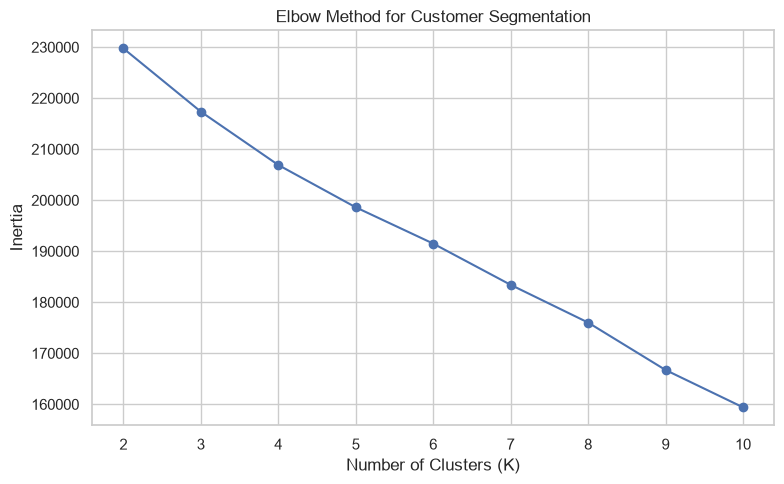

In [19]:

inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_train_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

## 9. Silhouette Analysis

The silhouette score measures how well-separated the clusters are. A higher score generally indicates better-defined groups.

We use this score alongside the Elbow Method and the business interpretability of the segments to select K.


,K,Silhouette_Score
0,2,0.129
1,3,0.118
2,4,0.112
3,5,0.130
4,6,0.134
5,7,0.156
6,8,0.149
7,9,0.169
8,10,0.178


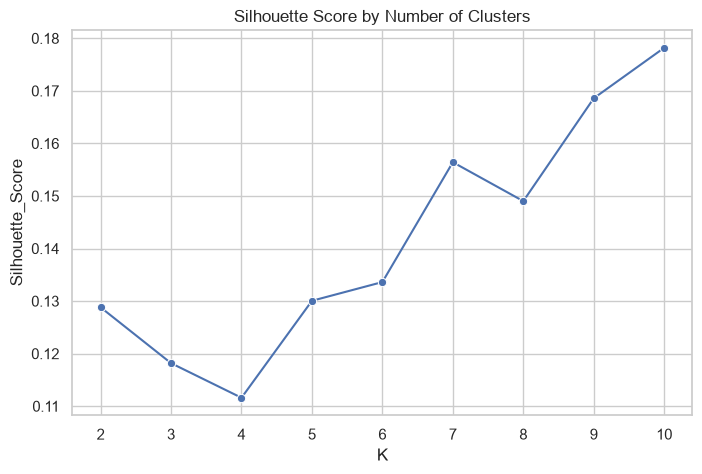

In [ ]:

silhouette_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_train_scaled)

    # Silhouette score requires at least 2 clusters
    # and fewer clusters than data points.
    score = silhouette_score(
        X_train_scaled,
        labels,
        sample_size=min(5000, len(X_train_scaled)),
        random_state=42
    )

    silhouette_results.append({
        "K": k,
        "Silhouette_Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)
display(silhouette_df.round(3))

plt.figure(figsize=(8, 5))
sns.lineplot(
    data=silhouette_df,
    x="K",
    y="Silhouette_Score",
    marker="o"
)
plt.title("Silhouette Score by Number of Clusters")
plt.show()

## 10. Train the K-Means Model

Based on the Elbow Method, silhouette scores, and interpretability, we choose the number of clusters.

The example below uses four clusters. Change `optimal_k` if your analysis supports a different number.


In [ ]:

optimal_k = 4  # Adjust after examining the plots

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

train_df["Cluster"] = kmeans.fit_predict(X_train_scaled)

print("K-Means clustering completed!")
print("\nCustomers per cluster:")
display(
    train_df["Cluster"]
    .value_counts()
    .sort_index()
)

K-Means clustering completed!

Customers per cluster:


Cluster
0    2511
1    1533
2    1959
3    2065
Name: count, dtype: int64

## 11. Cluster Visualisation

We visualise the discovered clusters using two combinations of numerical features. The cluster colours show how customers with similar characteristics are grouped.

These plots use the original feature values for interpretability; clustering itself uses the encoded and standardised feature matrix.


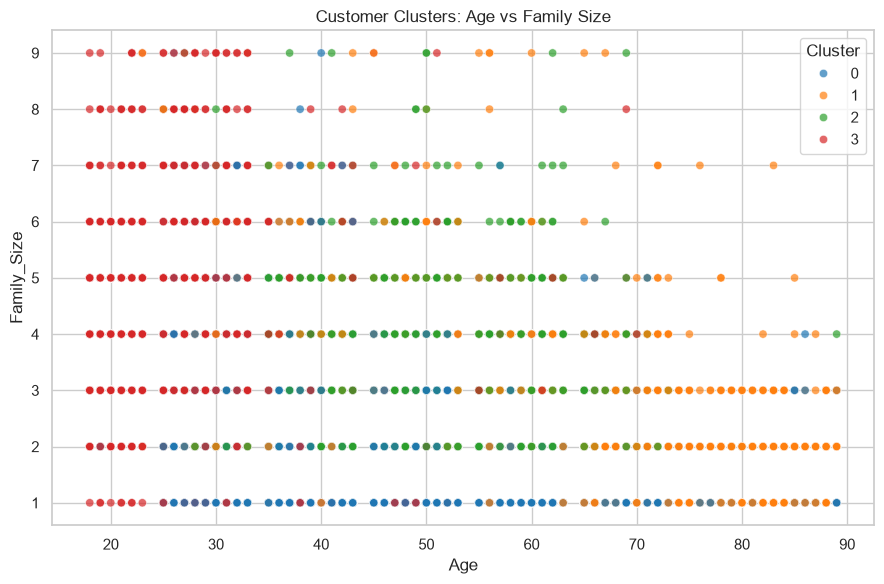

In [ ]:

plot_data = train_df.copy()

# Use median-imputed values for numerical visualisation
for col in ["Age", "Family_Size", "Work_Experience"]:
    if col in plot_data.columns:
        plot_data[col] = plot_data[col].fillna(
            plot_data[col].median()
        )

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=plot_data,
    x="Age",
    y="Family_Size",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("Customer Clusters: Age vs Family Size")
plt.tight_layout()
plt.show()

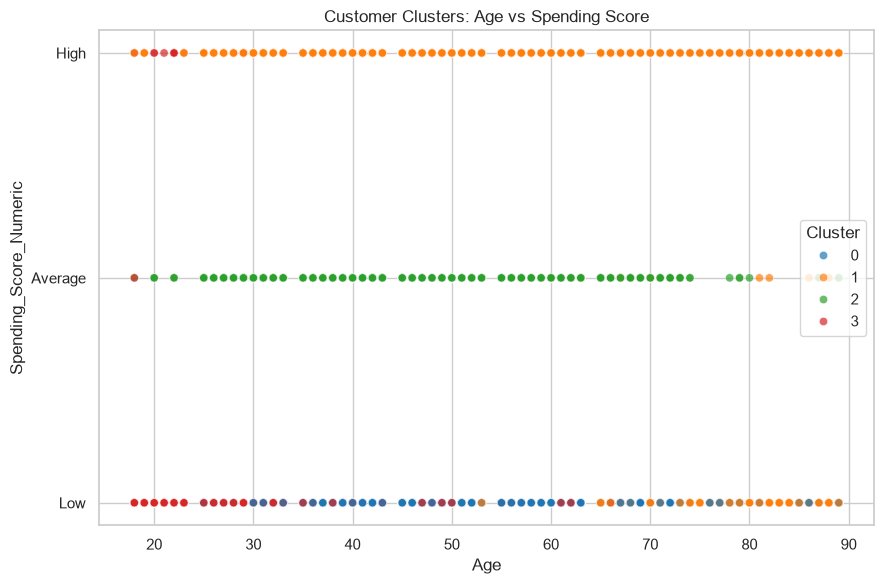

In [ ]:

if "Spending_Score" in plot_data.columns:
    spending_map = {
        "Low": 1,
        "Average": 2,
        "High": 3
    }

    plot_data["Spending_Score_Numeric"] = (
        plot_data["Spending_Score"]
        .astype(str)
        .str.strip()
        .str.title()
        .map(spending_map)
    )

    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        data=plot_data,
        x="Age",
        y="Spending_Score_Numeric",
        hue="Cluster",
        palette="tab10",
        alpha=0.7
    )

    plt.yticks([1, 2, 3], ["Low", "Average", "High"])
    plt.title("Customer Clusters: Age vs Spending Score")
    plt.tight_layout()
    plt.show()

## 12. Customer Segment Profiling

We calculate the mean values of numerical features for each cluster and examine categorical distributions.

This helps us describe the customer groups based on age, work experience, family size, and spending behaviour.


In [ ]:

numeric_profile_features = [
    col for col in
    ["Age", "Work_Experience", "Family_Size"]
    if col in train_df.columns
]

cluster_profile = train_df.groupby("Cluster").agg(
    Customer_Count=("Cluster", "size"),
    **{
        f"Average_{col}": (col, "mean")
        for col in numeric_profile_features
    }
)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"]
    / len(train_df) * 100
).round(2)

display(cluster_profile.round(2))

,Customer_Count,Average_Age,Average_Work_Experience,Average_Family_Size,Customer_Percentage
Cluster,,,,,
0,2511,42.73,3.20,2.00,31.12
1,1533,61.40,1.92,2.72,19.00
2,1959,46.70,2.52,3.11,24.28
3,2065,27.98,2.58,3.74,25.59


## 13. Customer Count by Cluster

We create a bar chart to compare the size of the discovered customer segments. This helps identify the largest and smallest groups for campaign planning.


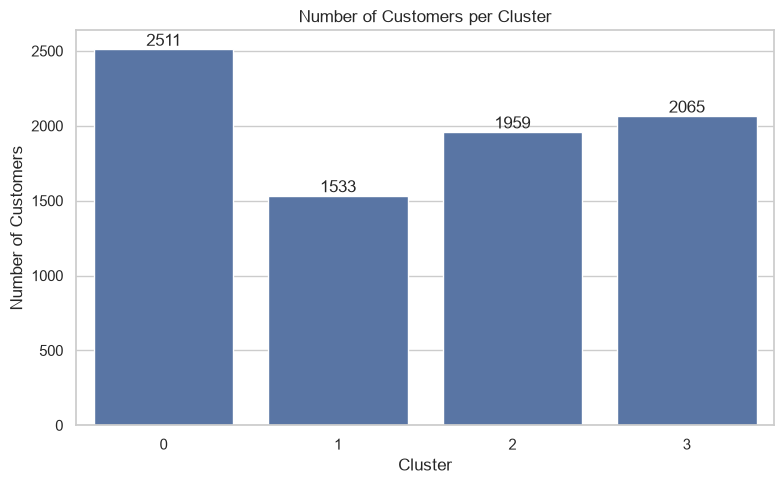

In [ ]:

cluster_counts = (
    train_df["Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values
)

ax.bar_label(ax.containers[0])

plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.title("Number of Customers per Cluster")
plt.tight_layout()
plt.show()

## 14. Marketing Recommendations

Customer clusters can help a business tailor campaigns to different customer profiles.

Possible strategies include:

* **High-spending customers:** Offer loyalty rewards, premium products, and exclusive promotions.
* **Moderate-spending customers:** Recommend relevant products and bundles to encourage further engagement.
* **Low-spending customers:** Use affordable product recommendations and carefully tested incentives.
* **Family-oriented customers:** Promote family bundles or multi-item offers when appropriate.
* **Distinct professional or demographic groups:** Personalise product recommendations only when the data supports a meaningful difference.

The clusters must be interpreted from their actual profiles. Cluster numbers are arbitrary and should not be treated as fixed customer categories.


In [ ]:

for cluster in sorted(train_df["Cluster"].unique()):
    group = train_df[train_df["Cluster"] == cluster]

    print(f"\nCluster {cluster}")
    print("=" * 35)
    print("Number of customers:", len(group))

    for col in numeric_profile_features:
        print(f"Average {col}: {group[col].mean():.2f}")

    if "Spending_Score" in group.columns:
        print("Spending score distribution:")
        print(
            group["Spending_Score"]
            .value_counts(normalize=True)
            .mul(100)
            .round(1)
            .astype(str) + "%"
        )

    if "Profession" in group.columns:
        print("Most common profession:",
              group["Profession"].mode().iloc[0]
              if not group["Profession"].mode().empty
              else "Unknown")


Cluster 0
Number of customers: 2511
Average Age: 42.73
Average Work_Experience: 3.20
Average Family_Size: 2.00
Spending score distribution:
Spending_Score
Low    100.0%
Name: proportion, dtype: str
Most common profession: Artist

Cluster 1
Number of customers: 1533
Average Age: 61.40
Average Work_Experience: 1.92
Average Family_Size: 2.72
Spending score distribution:
Spending_Score
High       78.4%
Low        20.7%
Average     0.8%
Name: proportion, dtype: str
Most common profession: Lawyer

Cluster 2
Number of customers: 1959
Average Age: 46.70
Average Work_Experience: 2.52
Average Family_Size: 3.11
Spending score distribution:
Spending_Score
Average    100.0%
Name: proportion, dtype: str
Most common profession: Artist

Cluster 3
Number of customers: 2065
Average Age: 27.98
Average Work_Experience: 2.58
Average Family_Size: 3.74
Spending score distribution:
Spending_Score
Low        99.2%
High        0.7%
Average     0.1%
Name: proportion, dtype: str
Most common profession: Healthcar

Cluster versus existing Segmentation labels:


Segmentation,A,B,C,D,All
Cluster,,,,,
0,898,655,399,559,2511
1,383,446,452,252,1533
2,338,589,898,134,1959
3,353,168,221,1323,2065
All,1972,1858,1970,2268,8068


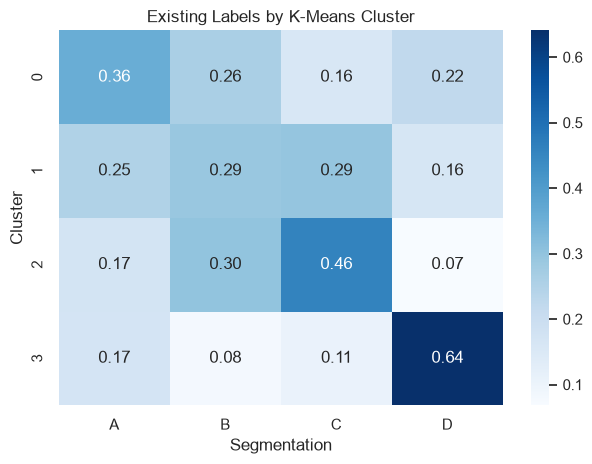

In [ ]:

if "Segmentation" in train_df.columns:
    print("Cluster versus existing Segmentation labels:")

    display(pd.crosstab(
        train_df["Cluster"],
        train_df["Segmentation"],
        margins=True
    ))

    sns.heatmap(
        pd.crosstab(
            train_df["Cluster"],
            train_df["Segmentation"],
            normalize="index"
        ),
        annot=True,
        fmt=".2f",
        cmap="Blues"
    )

    plt.title("Existing Labels by K-Means Cluster")
    plt.tight_layout()
    plt.show()

## 15. Apply Clustering to Test Customers

We use the preprocessing pipeline fitted on the training features to transform the test customers. We then assign each test customer to its nearest K-Means cluster.

The resulting cluster IDs can be exported for analysis. If the original competition expects the provided `Segmentation` labels instead of cluster IDs, those predictions require a separate supervised classification model.


In [ ]:

test_clusters = kmeans.predict(X_test_scaled)

test_output = pd.DataFrame({
    "ID": test_df["ID"],
    "Cluster": test_clusters
})

display(test_output.head())

test_output.to_csv(
    "test_customer_clusters.csv",
    index=False
)

print("Saved test_customer_clusters.csv")

,ID,Cluster
0,458989,0
1,458994,2
2,458996,0
3,459000,1
4,459001,3


Saved test_customer_clusters.csv


In [ ]:

train_df.to_csv("train_customer_segments.csv", index=False)
cluster_profile.to_csv("customer_cluster_profile.csv")

print("Files saved successfully:")
print("1. train_customer_segments.csv")
print("2. customer_cluster_profile.csv")
print("3. test_customer_clusters.csv")

Files saved successfully:
1. train_customer_segments.csv
2. customer_cluster_profile.csv
3. test_customer_clusters.csv


## 16. Conclusion

Customer segmentation was performed using K-Means clustering on demographic and spending-related features. The dataset was inspected, cleaned, and preprocessed to handle missing values and categorical variables. Numerical features were standardised using StandardScaler.

The Elbow Method and silhouette scores were used to evaluate the number of clusters. Customer segments were visualised using scatter plots and a bar chart, and cluster profiles were analysed to understand differences in customer characteristics and spending behaviour.

Marketing recommendations were developed based on the observed customer profiles. These segments can help businesses personalise product recommendations, improve customer engagement, and plan targeted marketing campaigns.

**Limitations:** The dataset does not contain transaction dates, order counts, or purchase amounts. Therefore, traditional RFM metrics, average purchase value, purchase frequency, and monetary customer lifetime value could not be calculated. Future work could incorporate transaction-level data to develop more comprehensive behavioural segments.

The effectiveness of the segmentation should be validated through marketing campaign performance, customer retention, and revenue metrics.


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Supervised prediction is separate from K-Means clustering.
if "Segmentation" not in train.columns:
    raise ValueError(
        "train.csv must contain Segmentation for this step."
    )

train_model = clean_column_names(train)
test_model = clean_column_names(test)
submission_template = clean_column_names(sample_submission)

feature_cols = [
    c for c in candidate_features
    if c in train_model.columns and c in test_model.columns
]

X = train_model[feature_cols]
y = train_model["Segmentation"]
X_test_final = test_model[feature_cols]

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in feature_cols if c not in num_cols]

preprocessor_clf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ]), cat_cols)
])

classifier = Pipeline([
    ("preprocessor", preprocessor_clf),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

classifier.fit(X, y)
predictions = classifier.predict(X_test_final)

submission = submission_template.copy()
submission["Segmentation"] = predictions

submission.to_csv("submission.csv", index=False)

display(submission.head())
print("Saved submission.csv")

,ID,Segmentation
0,458989,B
1,458994,C
2,458996,A
3,459000,C
4,459001,D


Saved submission.csv
